<a href="https://colab.research.google.com/github/2025cishaunaquindsouzab-sketch/Dav-Lab-Programs-4Ni25ci100/blob/main/Lab_six.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First five Rows
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]

 Dataset Shape
(1599, 12)

 Column Names
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

 Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
d

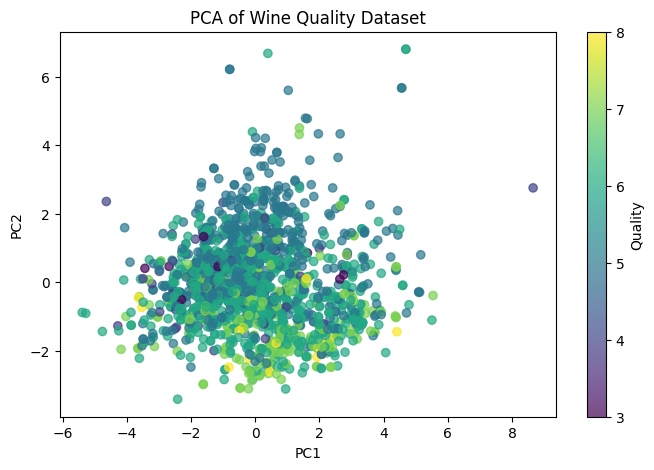

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# Load the Wine Quality dataset as requested
df = pd.read_csv('/content/winequality-red.csv')

print("First five Rows")
print(df.head())

print("\n Dataset Shape")
print(df.shape)

print("\n Column Names")
print(df.columns)

print("\n Missing Values:")
print(df.isnull().sum())

# Set features and target variable ('quality' exists in this dataset!)
x = df.drop("quality", axis=1)
y = df["quality"]

# Min-Max Normalization
normalizer = MinMaxScaler()
X_normalizer = normalizer.fit_transform(x)

print("\nNormalise data( First 5 Rows)")
print(pd.DataFrame(X_normalizer, columns=x.columns).head().round(3))

# Standardization
standardizer = StandardScaler()
X_standardizer = standardizer.fit_transform(x)

print("\nStandardize data( First 5 Rows)")
print(pd.DataFrame(X_standardizer, columns=x.columns).head().round(3))

pca = PCA(n_components=2)
x_pca = pca.fit_transform(X_standardizer)

print("\nPCA data( First 5 Rows)")
print(pd.DataFrame(x_pca, columns=["PC1", "PC2"]).head().round(3))

print("\noriginal number of features:", x.shape[1])
print("reduced number of features:", x_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("Total variance retained:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

plt.figure(figsize=(8, 5))
plt.scatter(x_pca[:, 0], x_pca[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Wine Quality Dataset")
plt.colorbar(label="Quality")
plt.show()

In [8]:
# Display descriptive statistics for the dataset
print("Descriptive Statistics of the Dataset:")
display(df.describe())

Descriptive Statistics of the Dataset:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000
